# Комплексний аналіз динаміки продажів торгівельної компанії
**Файл вхідних даних:** `Pr_1.xls`

Завдання:
1. Парсінг файлу параметрів
2. Попередній аналіз даних
3. Визначення показників ефективності — продажі та прибуток
4. Визначення математичної моделі даних відповідно до МНК (statsmodels OLS)
5. Динаміка зміни продажів за регіонами (таблиця, графік, файл)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.sandbox.regression.predstd import wls_prediction_std
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
%matplotlib inline

## 1. Парсінг файлу параметрів

In [2]:
d = pd.read_excel('Pr_1.xls', parse_dates=['Дата'])
print(d.shape)
d.head()

(27798, 11)


,Код магазину,Дата,Місяц,КільКість реалізацій,Собівартість одиниці,Ціна реализації,Unnamed: 6,Unnamed: 7,Unnamed: 8,Код магазину.1,Регіон
0,1370669,2021-01-01,Січень,1,88.6115,60.256891,NaN,NaN,NaN,1275815.0,Схід
1,1403429,2021-01-01,Січень,1,121.4205,107.032379,NaN,NaN,NaN,1270995.0,Схід
2,1463048,2021-01-01,Січень,2,109.6037,160.551244,NaN,NaN,NaN,1156378.0,Схід
3,1484789,2021-01-01,Січень,1,41.0083,48.161627,NaN,NaN,NaN,1153466.0,Схід
4,101462,2021-01-02,Січень,1,116.2402,144.495585,NaN,NaN,NaN,1172849.0,Схід


## 2. Попередній аналіз даних
Перевірка типів, пропусків, дублікатів та коректності значень стовпців.

In [3]:
d.info()

<class 'pandas.DataFrame'>
RangeIndex: 27798 entries, 0 to 27797
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Код магазину          27798 non-null  int64         
 1   Дата                  27798 non-null  datetime64[us]
 2   Місяц                 27798 non-null  str           
 3   КільКість реалізацій  27798 non-null  int64         
 4   Собівартість одиниці  27798 non-null  float64       
 5   Ціна реализації       27798 non-null  float64       
 6   Unnamed: 6            0 non-null      float64       
 7   Unnamed: 7            0 non-null      float64       
 8   Unnamed: 8            0 non-null      float64       
 9   Код магазину.1        199 non-null    float64       
 10  Регіон                199 non-null    str           
dtypes: datetime64[us](1), float64(6), int64(2), str(2)
memory usage: 2.3 MB


In [4]:
d.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Код магазину,27798.0,NaN,NaN,NaN,1204350.233794,101462.0,1147528.0,1168831.0,1310523.0,1503689.0,214784.545793
Дата,27798,NaN,NaN,NaN,2021-07-06 05:57:04.390244,2021-01-01 00:00:00,2021-03-20 00:00:00,2021-07-17 00:00:00,2021-10-11 00:00:00,2021-12-31 00:00:00,NaN
Місяц,27798,13,Лютий,2972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
КільКість реалізацій,27798.0,NaN,NaN,NaN,1.549824,-2.0,1.0,1.0,2.0,107.0,1.380311
Собівартість одиниці,27798.0,NaN,NaN,NaN,67.356526,7.2508,50.433,64.0,79.0,363.7716,22.725806
Ціна реализації,27798.0,NaN,NaN,NaN,76.717633,7.740853,56.517391,74.92106,90.863636,382.604348,26.955665
Unnamed: 6,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unnamed: 7,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unnamed: 8,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Код магазину.1,199.0,NaN,NaN,NaN,1215547.477387,101462.0,1149716.0,1171771.0,1300562.0,1503689.0,196802.890477


In [5]:
print('Пропуски по стовпцях:')
print(d.isna().sum())
print()
print('Унікальні значення "Місяц":')
print(d['Місяц'].unique())
print()
print('Кількість дублікатів рядків:', d.duplicated().sum())

Пропуски по стовпцях:
Код магазину                0
Дата                        0
Місяц                       0
КільКість реалізацій        0
Собівартість одиниці        0
Ціна реализації             0
Unnamed: 6              27798
Unnamed: 7              27798
Unnamed: 8              27798
Код магазину.1          27599
Регіон                  27599
dtype: int64

Унікальні значення "Місяц":
<StringArray>
[  'Січень',    'Лютий', 'Березень',  'Квітень',  'Травень',  'Червень',
   'Липень',  'Серпень', 'Вересень',  'Жовтень',  'Грудень', 'Листопад',
     'Стоп']
Length: 13, dtype: str

Кількість дублікатів рядків: 0


Останній рядок файлу містить службове значення `Стоп` (кінець таблиці) — видаляємо його. Також відкидаємо допоміжні порожні стовпці `Unnamed: 6/7/8` та вбудований у цю ж таблицю довідник `Код магазину.1` / `Регіон` (заповнений лише у перших 199 рядках) — його приєднаємо коректним `merge` у розділі 5.

In [6]:
d = d[d['Місяц'] != 'Стоп'].reset_index(drop=True)
d = d.drop(columns=[c for c in d.columns if str(c).startswith('Unnamed')] + ['Код магазину.1','Регіон'])
print('Розмір після очищення:', d.shape)
print('Період спостережень:', d['Дата'].min().date(), '-', d['Дата'].max().date())

Розмір після очищення: (27797, 6)
Період спостережень: 2021-01-01 - 2021-12-31


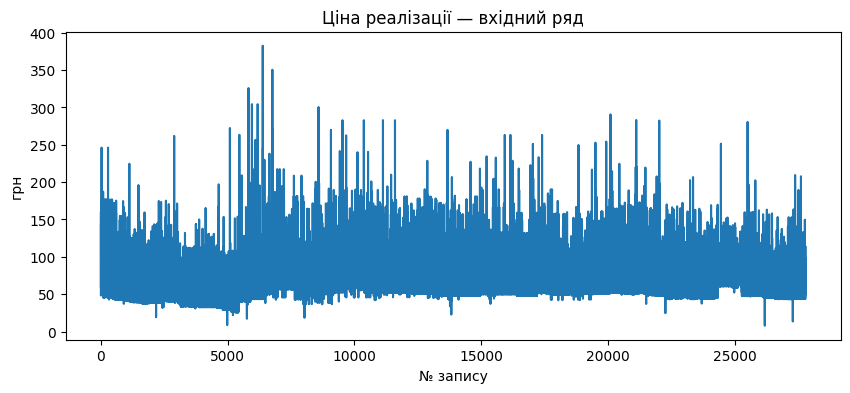

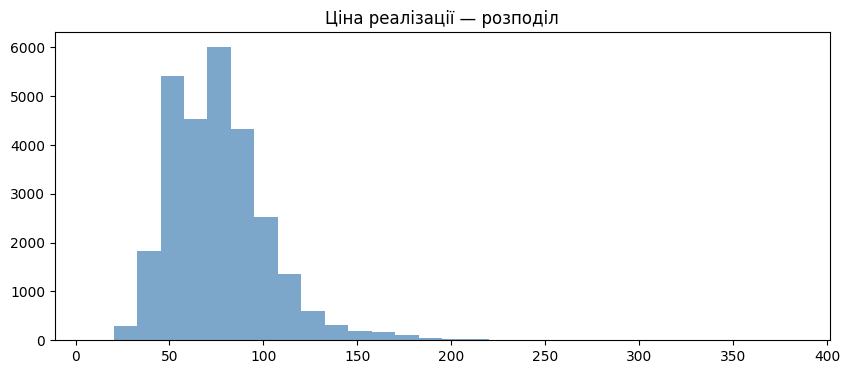

In [7]:
plt.figure(figsize=(10,4))
plt.title('Ціна реалізації — вхідний ряд')
plt.plot(d['Ціна реализації'].values)
plt.xlabel('№ запису'); plt.ylabel('грн')
plt.show()

plt.figure(figsize=(10,4))
plt.title('Ціна реалізації — розподіл')
plt.hist(d['Ціна реализації'], bins=30, facecolor='steelblue', alpha=0.7)
plt.show()

## 3. Визначення показників ефективності — продажі та прибуток
Продаж (оборот за собівартістю) = К-сть реалізацій × Собівартість одиниці.
Прибуток = К-сть реалізацій × (Ціна реалізації − Собівартість одиниці).

In [8]:
d['Продаж'] = d['КільКість реалізацій'] * d['Собівартість одиниці']
d['Прибуток'] = d['КільКість реалізацій'] * (d['Ціна реализації'] - d['Собівартість одиниці'])
d[['Дата','Місяц','КільКість реалізацій','Собівартість одиниці','Ціна реализації','Продаж','Прибуток']].head()

,Дата,Місяц,КільКість реалізацій,Собівартість одиниці,Ціна реализації,Продаж,Прибуток
0,2021-01-01,Січень,1,88.6115,60.256891,88.6115,-28.354609
1,2021-01-01,Січень,1,121.4205,107.032379,121.4205,-14.388121
2,2021-01-01,Січень,2,109.6037,160.551244,219.2074,101.895089
3,2021-01-01,Січень,1,41.0083,48.161627,41.0083,7.153327
4,2021-01-02,Січень,1,116.2402,144.495585,116.2402,28.255385


In [9]:
month_order = ['Січень','Лютий','Березень','Квітень','Травень','Червень',
               'Липень','Серпень','Вересень','Жовтень','Листопад','Грудень']
d['Місяц'] = pd.Categorical(d['Місяц'], categories=month_order, ordered=True)

monthly = d.groupby('Місяц', observed=True)[['Продаж','Прибуток']].sum()
monthly

,Продаж,Прибуток
Місяц,,
Січень,276638.4042,6302.837821
Лютий,352997.0000,-35441.849242
Березень,159901.0000,63411.168412
Квітень,146057.0000,33292.838641
Травень,149724.0000,40182.073095
Червень,170331.0000,34404.325974
Липень,239792.0000,36488.556562
Серпень,260189.0000,49418.183185
Вересень,244043.9927,32308.366134


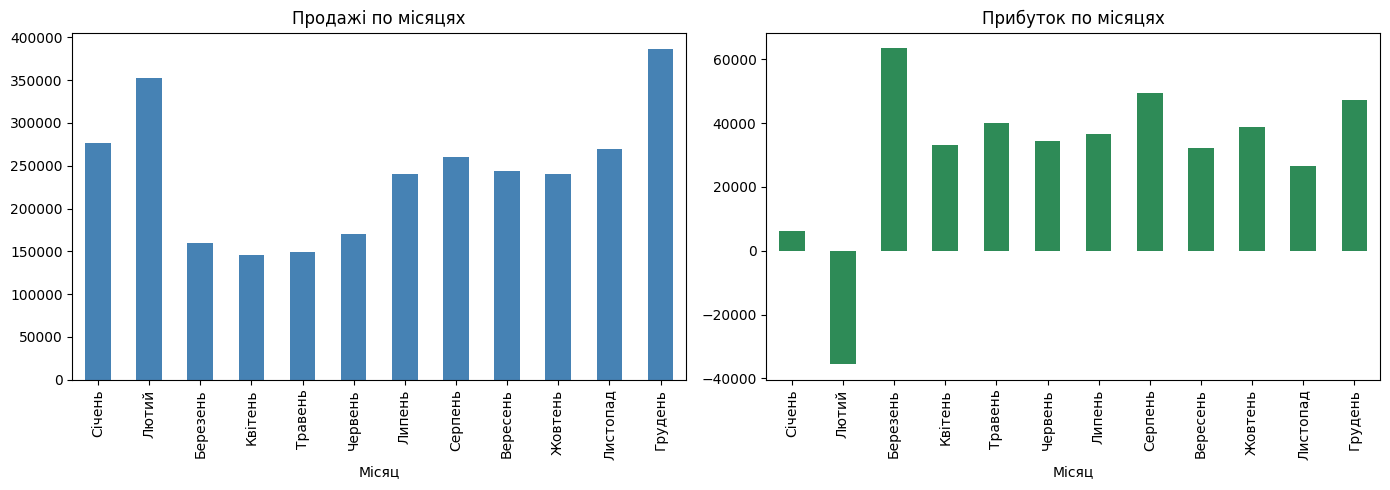

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))
monthly['Продаж'].plot(kind='bar', ax=ax[0], color='steelblue', title='Продажі по місяцях')
monthly['Прибуток'].plot(kind='bar', ax=ax[1], color='seagreen', title='Прибуток по місяцях')
plt.tight_layout()
plt.show()

## 4. Математична модель даних відповідно до МНК (statsmodels OLS)
Будуємо поліноміальну регресію 2-го степеня (аналог прикладу 1: `x, x^2`) для щомісячної динаміки продажів і прибутку, оцінюємо параметри, R² та довірчий інтервал прогнозу.

==== МНК-модель динаміки продажів (по місяцях) ====
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.587
Model:                            OLS   Adj. R-squared:                  0.496
Method:                 Least Squares   F-statistic:                     6.408
Date:                Wed, 16 Sep 2026   Prob (F-statistic):             0.0186
Time:                        14:21:31   Log-Likelihood:                -146.19
No. Observations:                  12   AIC:                             298.4
Df Residuals:                       9   BIC:                             299.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


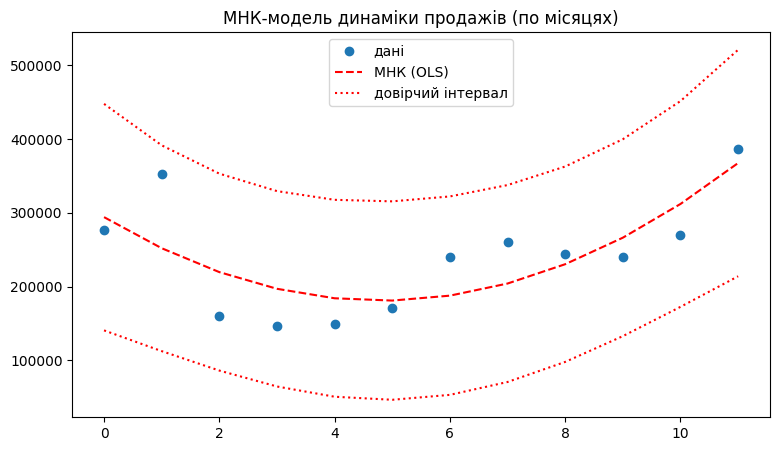

In [11]:
def ols_trend(y_series, title):
    y = y_series.values.astype(float)
    x = np.arange(len(y))
    X = sm.add_constant(np.column_stack((x, x**2)))
    model = sm.OLS(y, X)
    res = model.fit()
    print('====', title, '====')
    print(res.summary())
    print('Parameters:', res.params)
    print('R2:', res.rsquared)

    prstd, iv_l, iv_u = wls_prediction_std(res)
    fig, ax = plt.subplots(figsize=(9,5))
    ax.plot(x, y, 'o', label='дані')
    ax.plot(x, res.fittedvalues, 'r--', label='МНК (OLS)')
    ax.plot(x, iv_u, 'r:', label='довірчий інтервал')
    ax.plot(x, iv_l, 'r:')
    ax.set_title(title)
    ax.legend(loc='best')
    plt.show()
    return res

res_sale = ols_trend(monthly['Продаж'], 'МНК-модель динаміки продажів (по місяцях)')

==== МНК-модель динаміки прибутку (по місяцях) ====
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.326
Model:                            OLS   Adj. R-squared:                  0.176
Method:                 Least Squares   F-statistic:                     2.174
Date:                Wed, 16 Sep 2026   Prob (F-statistic):              0.170
Time:                        14:21:31   Log-Likelihood:                -135.67
No. Observations:                  12   AIC:                             277.3
Df Residuals:                       9   BIC:                             278.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------


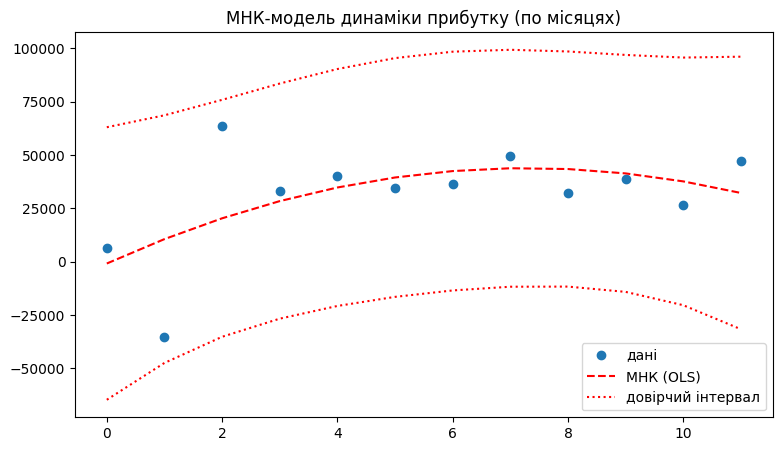

In [12]:
res_profit = ols_trend(monthly['Прибуток'], 'МНК-модель динаміки прибутку (по місяцях)')

## 5. Динаміка зміни продажів за регіонами (таблиця, графік, файл)
У файлі окремо міститься довідник відповідності «Код магазину» → «Регіон» (стовпці `Код магазину.1`, `Регіон`). Приєднуємо його до основної таблиці.

In [13]:
d_raw = pd.read_excel('Pr_1.xls')
region_map = d_raw[['Код магазину.1','Регіон']].dropna().drop_duplicates()
region_map = region_map.rename(columns={'Код магазину.1':'Код магазину'})
region_map['Код магазину'] = region_map['Код магазину'].astype(int)

d = d.merge(region_map, on='Код магазину', how='left')
print('Магазинів без визначеного регіону:', d['Регіон'].isna().sum())
d[['Код магазину','Регіон']].drop_duplicates().shape

Магазинів без визначеного регіону: 0


(199, 2)

In [14]:
region_total = d.groupby('Регіон')[['Продаж','Прибуток']].sum().sort_values('Продаж', ascending=False)
region_total

,Продаж,Прибуток
Регіон,,
Днепро-Слобідський,820706.3240,94860.256937
Центральний,791231.2903,111436.353788
Західний,717395.9491,87716.364690
Південний,514336.3064,70535.373622
Схід,52036.5505,8402.649028


In [15]:
region_month = d.pivot_table(index='Місяц', columns='Регіон', values='Продаж',
                              aggfunc='sum', observed=True).reindex(month_order)
region_month

Регіон,Днепро-Слобідський,Західний,Південний,Схід,Центральний
Місяц,,,,,
Січень,80186.5552,70958.1058,49905.9213,7348.2234,68239.5985
Лютий,101711.0000,93697.0000,54959.0000,7596.0000,95034.0000
Березень,42223.0000,37061.0000,32145.0000,4558.0000,43914.0000
Квітень,45095.0000,33250.0000,26349.0000,2995.0000,38368.0000
Травень,44454.0000,34263.0000,26825.0000,2511.0000,41671.0000
Червень,46799.0000,40909.0000,29684.0000,2833.0000,50106.0000
Липень,68069.0000,60301.0000,44928.0000,3353.0000,63141.0000
Серпень,78557.0000,68137.0000,42405.0000,5370.0000,65720.0000
Вересень,70127.1318,63691.3387,38409.6960,3111.5967,68704.2295


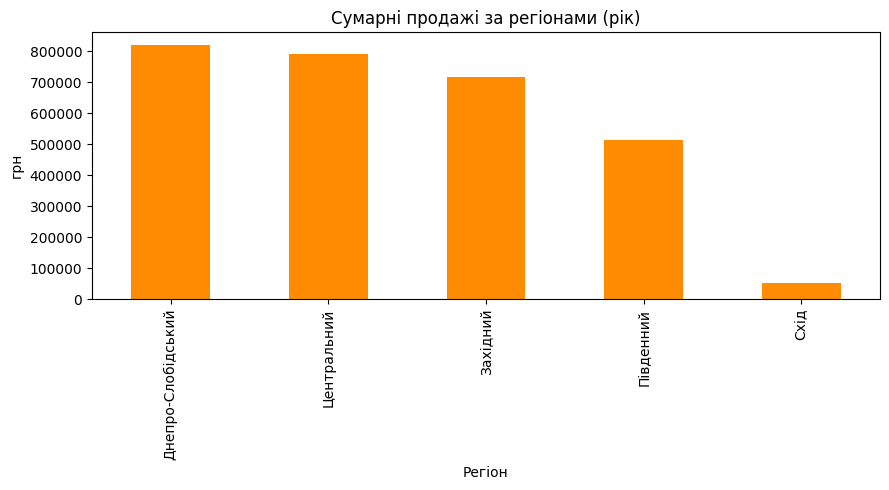

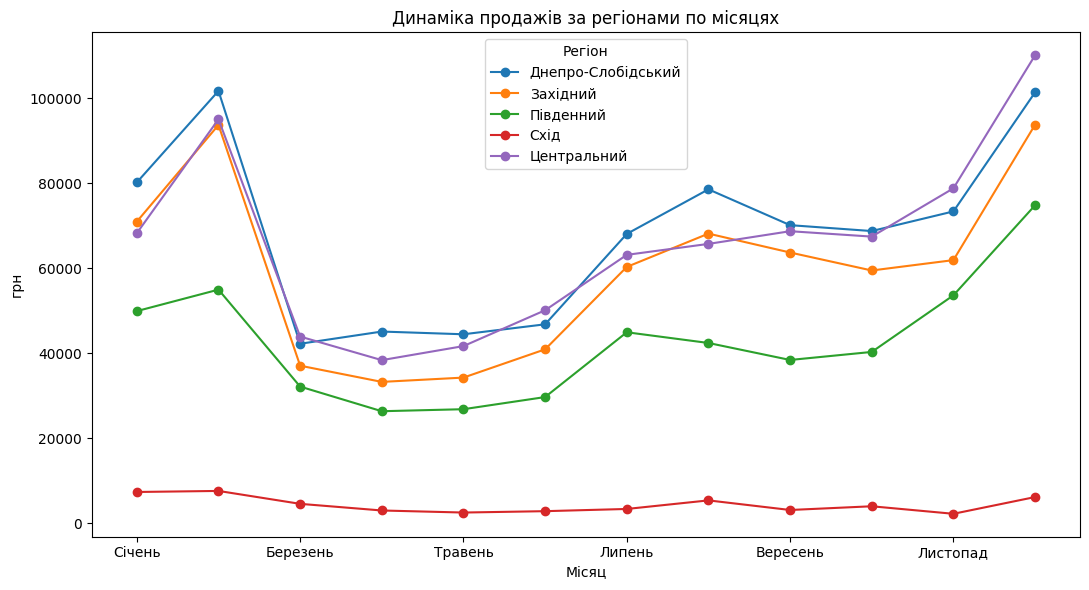

In [16]:
fig, ax = plt.subplots(figsize=(9,5))
region_total['Продаж'].plot(kind='bar', ax=ax, color='darkorange')
ax.set_title('Сумарні продажі за регіонами (рік)')
ax.set_ylabel('грн')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11,6))
region_month.plot(ax=ax, marker='o')
ax.set_title('Динаміка продажів за регіонами по місяцях')
ax.set_ylabel('грн')
plt.tight_layout()
plt.show()

Збереження результатів по регіонах у окремий Excel-файл.

In [17]:
with pd.ExcelWriter('region_sales_report.xlsx') as writer:
    region_total.to_excel(writer, sheet_name='Регіони_сума')
    region_month.to_excel(writer, sheet_name='Регіони_по_місяцях')

print('Файл region_sales_report.xlsx збережено')

Файл region_sales_report.xlsx збережено


## Висновок
Дані очищено від службового рядка `Стоп`; побудовано показники продажів і прибутку на рівні кожного запису та в розрізі місяців. МНК-моделі (OLS, поліном 2-го степеня) показують загальний тренд динаміки продажів і прибутку протягом року з довірчим інтервалом прогнозу. Найбільші обсяги продажів дає регіон **Дніпро-Слобідський**, а мінімальні — регіон **Схід**. Результати по регіонах (сумарно та по місяцях) збережено у файл `region_sales_report.xlsx`.